In [26]:
import wandb
import pandas as pd
api = wandb.Api()

In [ ]:
runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "jobType": "finetuning",
    "group": {"$ne": None}
})

In [28]:
df = pd.DataFrame([
    run.summary._json_dict | {
        "name": run.name,
        "id": run.id,
        "tags": run.tags,
        "group": run.group,
        "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
        "orients_promoters": run.config.get("canonicalization", {}).get("orient_promoters", False)
    }
    for run in runs
])

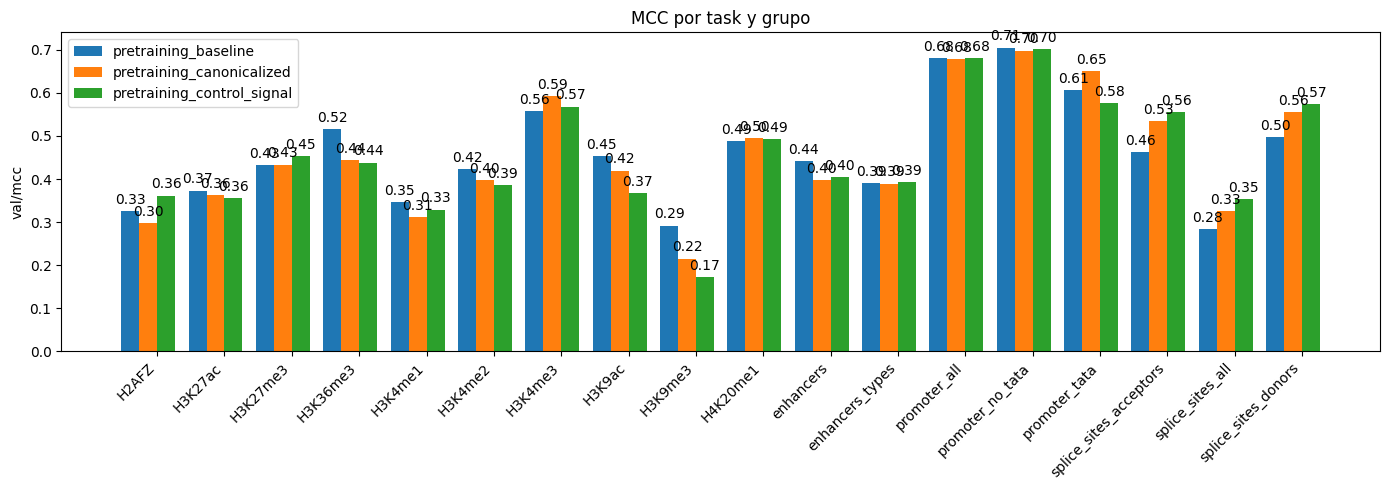

In [29]:
import matplotlib.pyplot as plt
import numpy as np

groups = sorted(df["group"].dropna().unique())
tasks = sorted(df["downstream_task"].dropna().unique())

x = np.arange(len(tasks))
width = 0.8 / len(groups)

fig, ax = plt.subplots(figsize=(14, 5))

bar_containers = []
for i, group in enumerate(groups):
    vals = [
        df[(df["group"] == group) & (df["downstream_task"] == t)]["val/mcc"].mean()
        for t in tasks
    ]
    # Replace NaNs with 0 for plotting so bars render cleanly
    vals = np.nan_to_num(vals, nan=0.0)
    bars = ax.bar(x + i * width - width * len(groups) / 2, vals, width, label=group)
    bar_containers.append(bars)

# Add labels on each bar (showing three decimals)
for container in bar_containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(tasks, rotation=45, ha="right")
ax.set_ylabel("val/mcc")
ax.set_title("MCC por task y grupo")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Filtrar solo el grupo pretrain_canonicalized
df_filtered = df[df["group"] == "pretrain_canonicalized"].copy()

tasks = sorted(df_filtered["downstream_task"].dropna().unique())
orient_vals = [True, False]
labels = {True: "Orient promoters", False: "No orient"}
colors = {True: "#4C72B0", False: "#DD8452"}

x = np.arange(len(tasks))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 5))

for i, orient in enumerate(orient_vals):
    vals = [
        df_filtered[
            (df_filtered["orients_promoters"] == orient) &
            (df_filtered["downstream_task"] == t)
        ]["val/mcc"].mean()
        for t in tasks
    ]
    vals = np.nan_to_num(vals, nan=0.0)
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, vals, width, label=labels[orient], color=colors[orient])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(tasks, rotation=45, ha="right")
ax.set_ylabel("val/mcc")
ax.set_title("MCC por downstream task — Orient promoters vs No orient (pretrain_canonicalized)")
ax.legend()
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)  # un poco de espacio para las etiquetas

plt.tight_layout()
plt.show()